# steps in simulation

- 26% community was black. 
- 10-15% of panel members were black  
- 12 members. 

- simulate one jury member. 
  - 26% black 74% white. 
  - pick a number from 0-99 (1-100)  
    - 1-26 black person. 
    - 27-100 white person. 
<br>

- repeat one jury member simulation 12 times
<br>

- repeat whole jury X times - X should be large 
  - simulate one jury
    - simulate one person
  - save result
  - repeat
<br>

- result is number of black jurors in 1000 (X) juries
- plot as a distribution
- ask question - is 0 common or uncommon?



In [17]:
np.random.choice([1,0],p=[.26,.74],size=12)

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0])

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [16]:
def simulate_jury(percent_black):
    percent_white = 1-percent_black
    # one way to simulate 26% black - a different way is below
    jury_members = np.random.choice([1,0],size=12,p=[percent_black,percent_white])
    return(jury_members)

my_jury = simulate_jury(.26)
print(my_jury)

[0 0 0 0 0 0 1 0 0 0 0 0]


In [22]:
# counting black members

# note!  a different way to simulate - using 12 integers between 0 and 99
jury = np.random.randint(low=0, high=100, size=12)
print(jury)
black_members = jury < 26
print(black_members)
num_black = np.sum(black_members)
print(num_black)

[44  5  2 23 32 11 89 44  4 44 81  1]
[False  True  True  True False  True False False  True False False  True]
6


### Solution

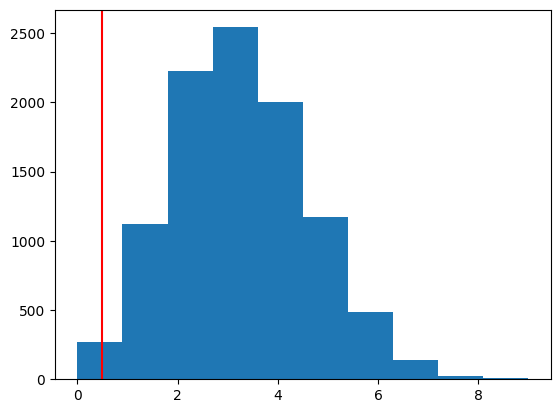

In [23]:

# prepare for loop
percent_black = .26

number_of_simulations = 10000
num_black_jurors = np.full(number_of_simulations,np.nan)

# loop
for i in np.arange(0,number_of_simulations):
    one_jury = simulate_jury(percent_black)
    num_black_jurors[i] = np.sum(one_jury) # count black members

#print(num_black_jurors)
# show result - first plot then probability
plt.hist(num_black_jurors)
plt.axvline(0.5,color="red") # 0.5 to mark middle of the 0 - 1 space

In [24]:
# probability

count_eq_zero = np.sum(num_black_jurors == 0)
print("number of juries with 0 black members out of ",number_of_simulations," juries = ",count_eq_zero)
p_fair = count_eq_zero/number_of_simulations
print("Probability that jury selection was fair: ",p_fair)

number of juries with 0 black members out of  10000  juries =  269
Probability that jury selection was fair:  0.0269
